In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/sample_submission.csv
/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/train.csv
/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/metadata.csv
/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/test.csv


# **Heavy Equipment Selling Price Prediction Challenge**

## **IMPORTING MODULES**

In [2]:
import numpy as np
import pandas as pd

# for visualization
import matplotlib.pyplot as plt
import seaborn as sns

# preprocessing
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import KFold

# models
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from lightgbm import LGBMRegressor

# metrics
from sklearn.metrics import mean_squared_log_error

import warnings
warnings.filterwarnings("ignore")

import lightgbm as lgb

print("Modules imported")

Modules imported


## **LOADING THE DATA**

In [3]:
DATA_PATH = "/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge"

train = pd.read_csv(f"{DATA_PATH}/train.csv", low_memory=False)
test = pd.read_csv(f"{DATA_PATH}/test.csv", low_memory=False)
sample_sub = pd.read_csv(f"{DATA_PATH}/sample_submission.csv")

TARGET_COL = "TargetValue"
ID_COL = "TransactionID"

print("Train shape:", train.shape)
print("Test shape:", test.shape)
print(train.dtypes.value_counts())

Train shape: (138701, 50)
Test shape: (15000, 49)
object     44
int64       4
float64     2
Name: count, dtype: int64


## **EDA**

##  Target variable distribution

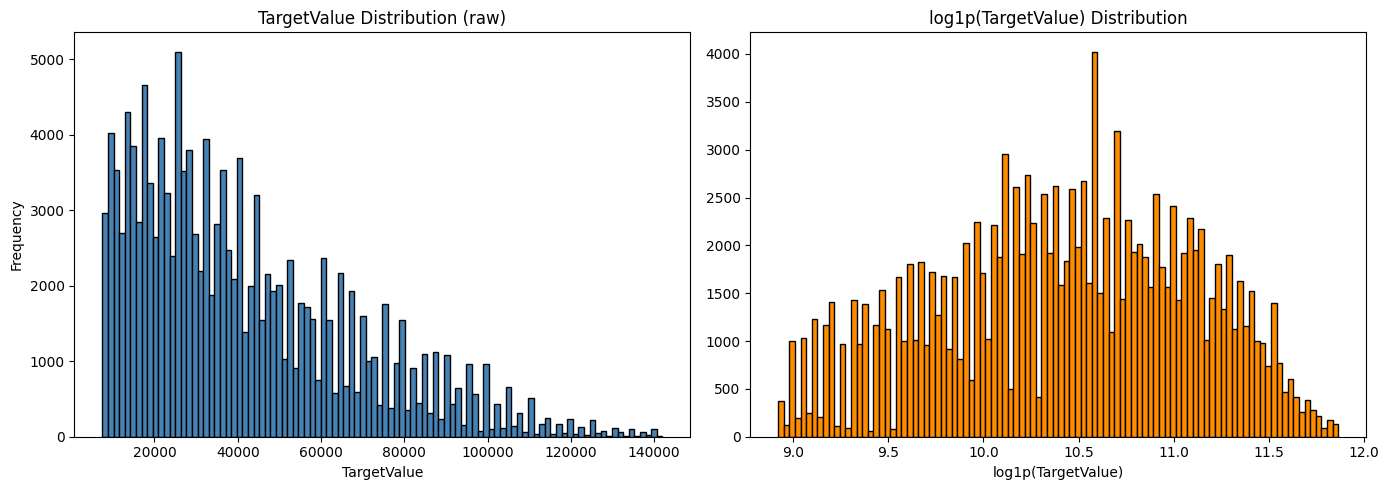

Raw skew: 0.97
Log skew: -0.198


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(train[TARGET_COL], bins=100, color="steelblue", edgecolor="black")
axes[0].set_title("TargetValue Distribution (raw)")
axes[0].set_xlabel("TargetValue")
axes[0].set_ylabel("Frequency")

axes[1].hist(np.log1p(train[TARGET_COL]), bins=100, color="darkorange", edgecolor="black")
axes[1].set_title("log1p(TargetValue) Distribution")
axes[1].set_xlabel("log1p(TargetValue)")

plt.tight_layout()
plt.show()

print("Raw skew:", round(train[TARGET_COL].skew(), 3))
print("Log skew:", round(np.log1p(train[TARGET_COL]).skew(), 3))

##  Missing values overview

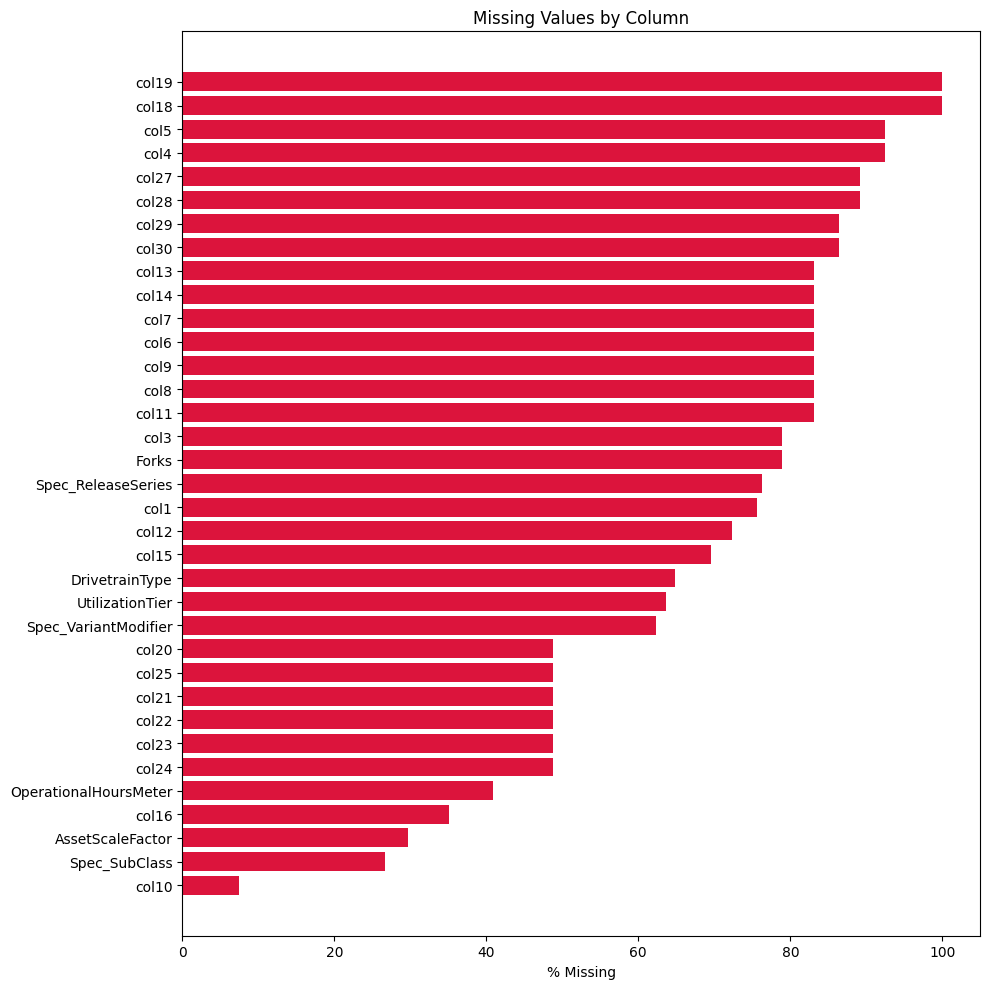

col19                    99.952416
col18                    99.952416
col5                     92.515555
col4                     92.515555
col27                    89.214930
col28                    89.214930
col29                    86.393753
col30                    86.393753
col13                    83.125572
col14                    83.125572
col7                     83.125572
col6                     83.125572
col9                     83.125572
col8                     83.125572
col11                    83.125572
col3                     78.909309
Forks                    78.861724
Spec_ReleaseSeries       76.282795
col1                     75.641127
col12                    72.340502
col15                    69.519326
DrivetrainType           64.856057
UtilizationTier          63.608770
Spec_VariantModifier     62.269919
col20                    48.799216
col25                    48.799216
col21                    48.799216
col22                    48.797774
col23               

In [5]:
missing = train.isnull().mean().sort_values(ascending=False) * 100
missing = missing[missing > 0]

fig, ax = plt.subplots(figsize=(10, 10))
ax.barh(missing.index, missing.values, color="crimson")
ax.set_xlabel("% Missing")
ax.set_title("Missing Values by Column")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

print(missing)

## Univariate feature analysis
Looking at individual feature distributions before checking their relationship with price.

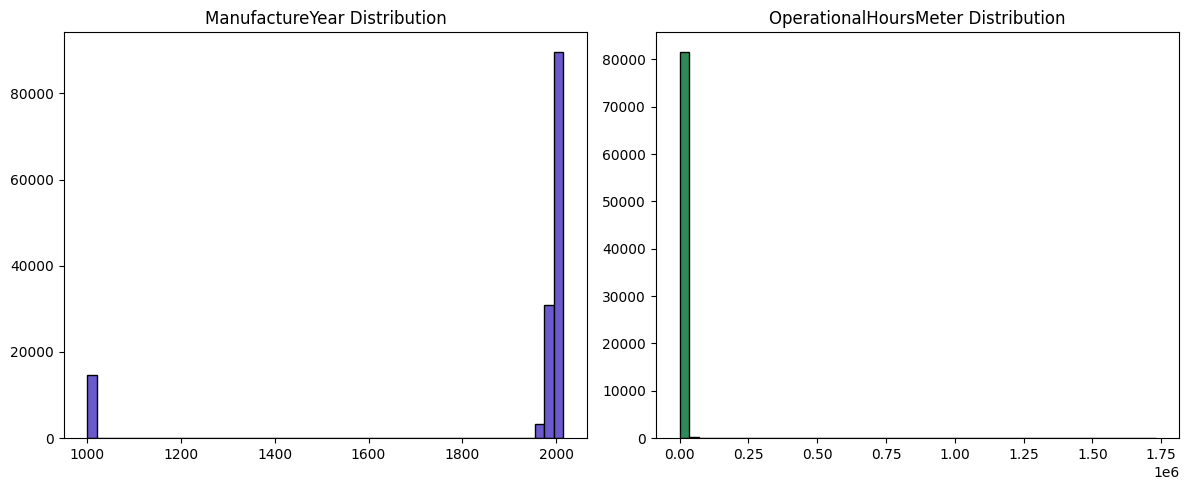

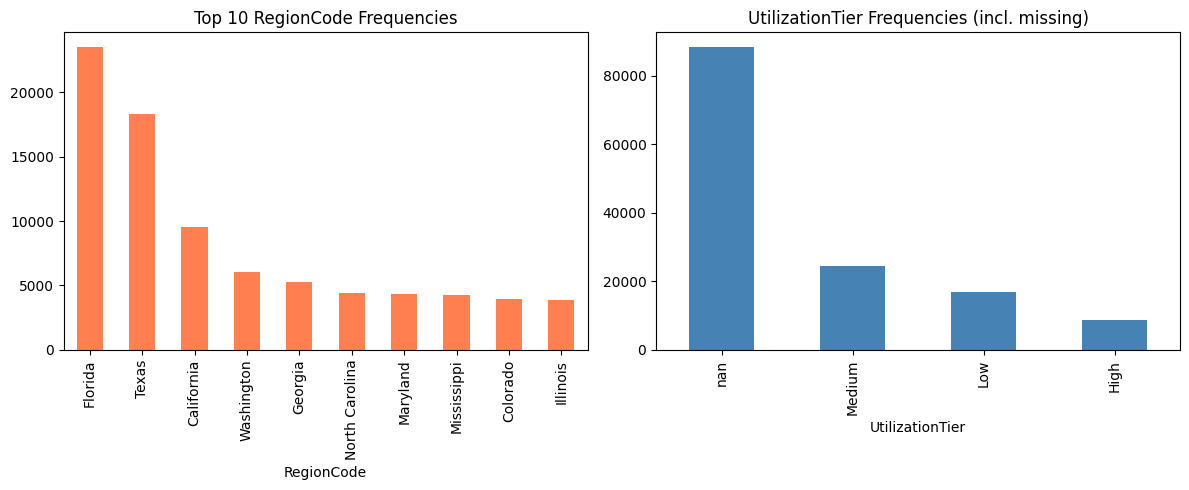

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].hist(train["ManufactureYear"].dropna(), bins=50, color="slateblue", edgecolor="black")
axes[0].set_title("ManufactureYear Distribution")

axes[1].hist(train["OperationalHoursMeter"].dropna(), bins=50, color="seagreen", edgecolor="black")
axes[1].set_title("OperationalHoursMeter Distribution")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
train["RegionCode"].value_counts().head(10).plot(kind="bar", ax=axes[0], color="coral")
axes[0].set_title("Top 10 RegionCode Frequencies")

train["UtilizationTier"].value_counts(dropna=False).plot(kind="bar", ax=axes[1], color="steelblue")
axes[1].set_title("UtilizationTier Frequencies (incl. missing)")
plt.tight_layout()
plt.show()

## Numeric feature vs target (Bivariate)
Checking if ManufactureYear and OperationalHoursMeter actually relate to price.

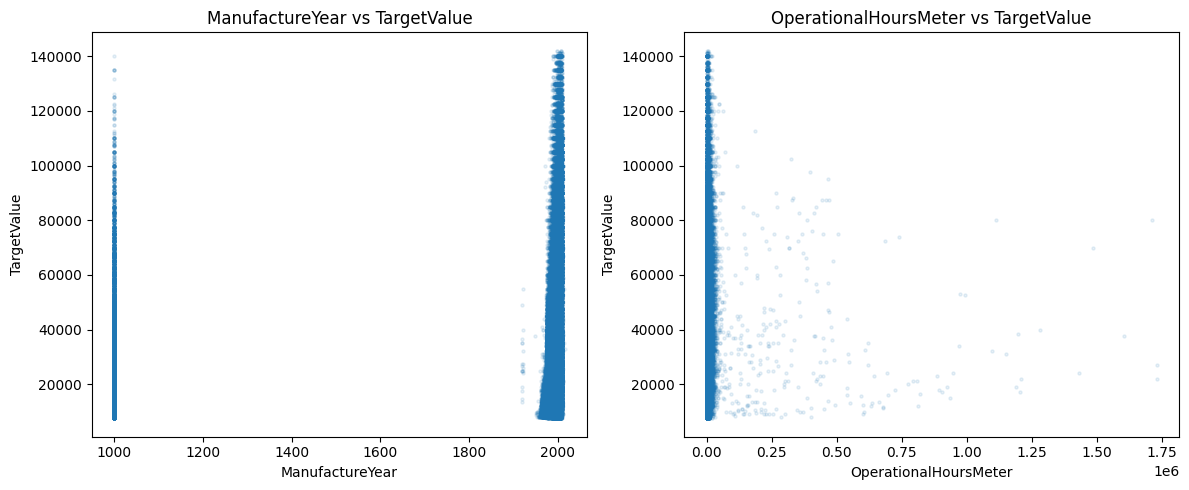

In [7]:
num_cols = ["ManufactureYear", "OperationalHoursMeter"]

fig, axes = plt.subplots(1, len(num_cols), figsize=(12, 5))
for i, col in enumerate(num_cols):
    axes[i].scatter(train[col], train[TARGET_COL], alpha=0.1, s=5)
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("TargetValue")
    axes[i].set_title(f"{col} vs TargetValue")
plt.tight_layout()
plt.show()

## Categorical feature vs target
Checking if price differs across RegionCode, UtilizationTier, CabinType.


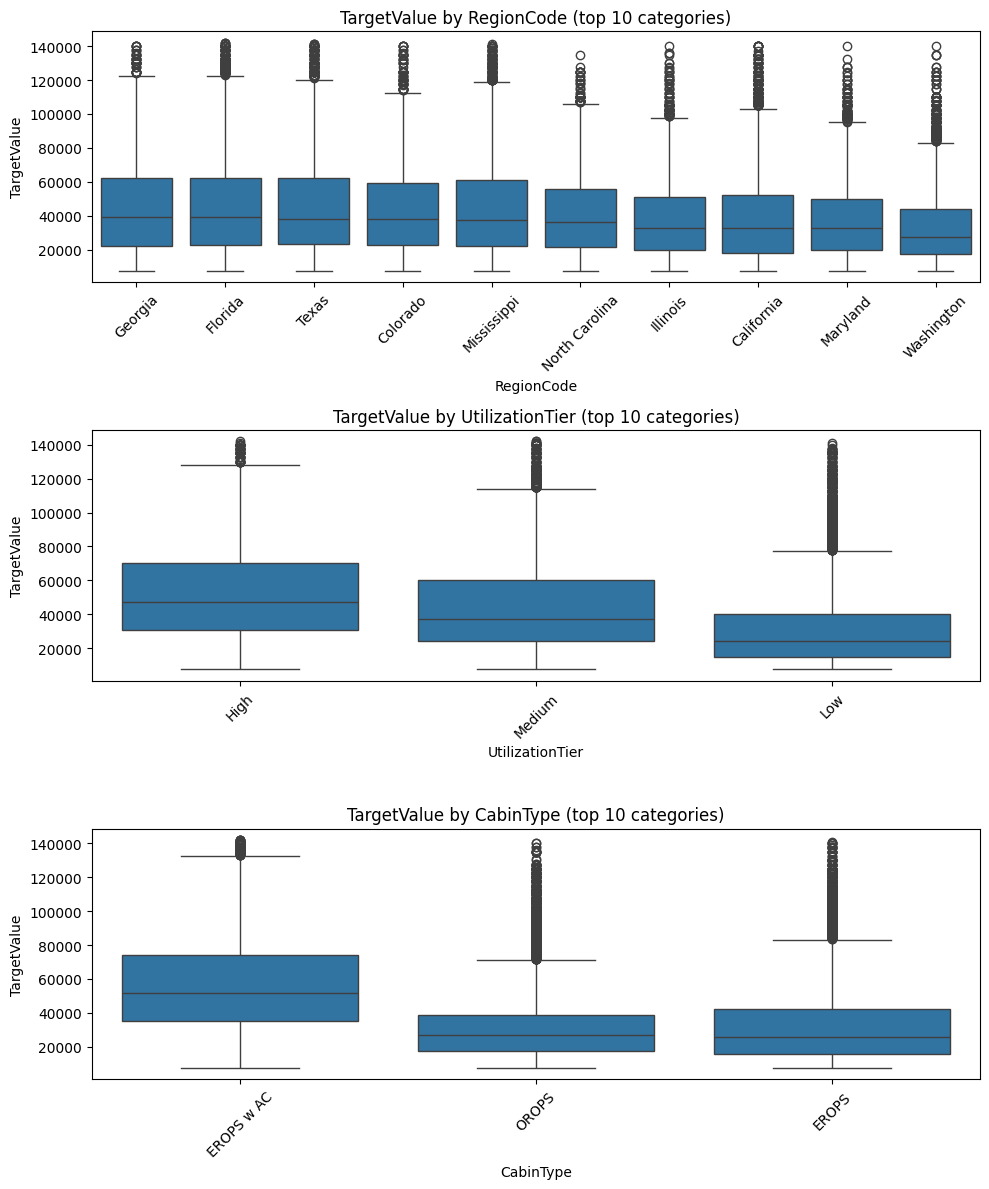

In [8]:
cat_cols = ["RegionCode", "UtilizationTier", "CabinType"]

fig, axes = plt.subplots(len(cat_cols), 1, figsize=(10, 4 * len(cat_cols)))
for i, col in enumerate(cat_cols):
    top_cats = train[col].value_counts().head(10).index
    subset = train[train[col].isin(top_cats)]
    order = subset.groupby(col)[TARGET_COL].median().sort_values(ascending=False).index
    sns.boxplot(x=col, y=TARGET_COL, data=subset, order=order, ax=axes[i])
    axes[i].set_title(f"TargetValue by {col} (top 10 categories)")
    axes[i].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

## High-cardinality check
Checking which categorical columns have too many unique values for one-hot encoding.

In [9]:
high_card_cols = ["Spec_BaseClass", "Spec_SubClass", "FunctionalClassification", "ProductConfigID"]
for col in high_card_cols:
    print(f"{col}: {train[col].nunique()} unique values")

Spec_BaseClass: 1249 unique values
Spec_SubClass: 147 unique values
FunctionalClassification: 65 unique values
ProductConfigID: 3594 unique values


## Sale date patterns
Checking if price changes based on year or month of sale.

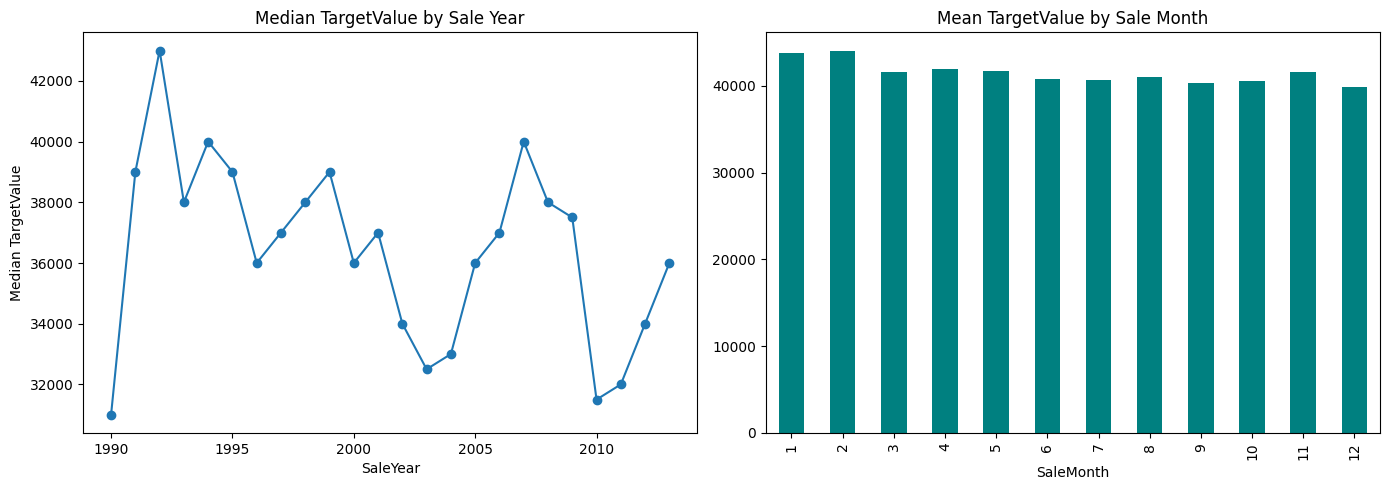

In [10]:
train["TransactionDate"] = pd.to_datetime(train["TransactionDate"])
train["SaleYear"] = train["TransactionDate"].dt.year
train["SaleMonth"] = train["TransactionDate"].dt.month

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

train.groupby("SaleYear")[TARGET_COL].median().plot(ax=axes[0], marker="o")
axes[0].set_title("Median TargetValue by Sale Year")
axes[0].set_ylabel("Median TargetValue")

train.groupby("SaleMonth")[TARGET_COL].mean().plot(ax=axes[1], kind="bar", color="teal")
axes[1].set_title("Mean TargetValue by Sale Month")

plt.tight_layout()
plt.show()

## Feature Engineering
Making new features like asset age and usage rate from existing columns.


In [11]:
def engineer_features(df):
    df = df.copy()
    
    # dates
    df["TransactionDate"] = pd.to_datetime(df["TransactionDate"])
    df["SaleYear"] = df["TransactionDate"].dt.year
    df["SaleMonth"] = df["TransactionDate"].dt.month
    
    # ManufactureYear placeholder codes (1000/1001) are not real years
    df["ManufactureYear"] = df["ManufactureYear"].replace([1000, 1001], np.nan)
    
    # asset age
    df["AssetAge"] = df["SaleYear"] - df["ManufactureYear"]
    
    # OperationalHoursMeter has extreme outliers - cap at 99th percentile (computed on train only)
    df["OperationalHoursMeter"] = df["OperationalHoursMeter"].clip(upper=HOURS_CAP)
    
    # usage intensity
    df["HoursPerYear"] = df["OperationalHoursMeter"] / df["AssetAge"].replace(0, np.nan)
    df["HoursPerYear"] = df["HoursPerYear"].replace([np.inf, -np.inf], np.nan)
    
    # descriptor string length as a proxy for spec richness
    df["DescriptorLength"] = df["Spec_FullDescriptor"].astype(str).str.len()
    
    # missingness flags for the two heavily-missing "meaningful absence" columns
    df["HasOperationalHours"] = df["OperationalHoursMeter"].notna().astype(int)
    df["HasVariantModifier"] = df["Spec_VariantModifier"].notna().astype(int)
    
    return df

# compute the cap from TRAIN only, then reuse for both
HOURS_CAP = train["OperationalHoursMeter"].quantile(0.99)
print("99th percentile hours cap:", HOURS_CAP)

train = engineer_features(train)
test = engineer_features(test)

print("New train shape:", train.shape)
train[["AssetAge", "HoursPerYear", "DescriptorLength"]].describe()

99th percentile hours cap: 25796.00999999995
New train shape: (138701, 57)


,AssetAge,HoursPerYear,DescriptorLength
count,123982.000000,72814.000000,138701.000000
mean,10.037957,455.785227,5.437654
std,7.418629,610.035929,1.768494
min,-7.000000,-2267.000000,2.000000
25%,5.000000,0.000000,4.000000
50%,8.000000,320.000000,5.000000
75%,13.000000,715.750000,7.000000
max,92.000000,25796.010000,19.000000


## Handling High-Missingness Columns
Dropping columns that are missing in >85% of rows - not enough data to fill in reliably.

In [12]:
missing_pct = train.isnull().mean().sort_values(ascending=False) * 100
print(missing_pct.head(25))
cols_to_drop = missing_pct[missing_pct > 85].index.tolist()
print(cols_to_drop)

train = train.drop(columns=cols_to_drop)
test = test.drop(columns=[c for c in cols_to_drop if c in test.columns])

print("Train shape:", train.shape)
print("Test shape:", test.shape)

col18                   99.952416
col19                   99.952416
col5                    92.515555
col4                    92.515555
col28                   89.214930
col27                   89.214930
col29                   86.393753
col30                   86.393753
col6                    83.125572
col8                    83.125572
col7                    83.125572
col9                    83.125572
col11                   83.125572
col14                   83.125572
col13                   83.125572
col3                    78.909309
Forks                   78.861724
Spec_ReleaseSeries      76.282795
col1                    75.641127
col12                   72.340502
col15                   69.519326
DrivetrainType          64.856057
UtilizationTier         63.608770
Spec_VariantModifier    62.269919
col25                   48.799216
dtype: float64
['col18', 'col19', 'col5', 'col4', 'col28', 'col27', 'col29', 'col30']
Train shape: (138701, 49)
Test shape: (15000, 48)


In [13]:
# checking if columns dropped
print(train.shape)  
print([c for c in ["col18","col19","col5","col4","col27","col28","col29","col30"] if c in train.columns])

(138701, 49)
[]


## Train/Validation Split
Splitting before encoding so target encoding doesn't leak into validation.

In [14]:
exclude_cols = ["TransactionID", "AssetID", "TargetValue", "TransactionDate"]
feature_cols = [c for c in train.columns if c not in exclude_cols]

X = train[feature_cols]
y = np.log1p(train["TargetValue"])  # training on log scale, matches RMSLE

X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(X_train.shape, X_valid.shape)

(110960, 45) (27741, 45)


## Imputation
Filling missing values - median for numbers, most frequent for categories.


In [15]:
cat_cols = X_train.select_dtypes(include="object").columns.tolist()
num_cols = X_train.select_dtypes(include=np.number).columns.tolist()

cardinality = X_train[cat_cols].nunique().sort_values(ascending=False)
print(cardinality)

HIGH_CARD_THRESHOLD = 20
high_card_cols = cardinality[cardinality > HIGH_CARD_THRESHOLD].index.tolist()
low_card_cols = cardinality[cardinality <= HIGH_CARD_THRESHOLD].index.tolist()

# Spec_FullDescriptor already summarized via DescriptorLength (Step 3) - drop it
# from target encoding to avoid a near-useless, leakage-prone feature
high_card_cols = [c for c in high_card_cols if c != "Spec_FullDescriptor"]

print("High-cardinality columns:", high_card_cols)
print("Low-cardinality columns:", low_card_cols)

num_imputer = SimpleImputer(strategy="median")
X_train_num = pd.DataFrame(num_imputer.fit_transform(X_train[num_cols]), columns=num_cols, index=X_train.index)
X_valid_num = pd.DataFrame(num_imputer.transform(X_valid[num_cols]), columns=num_cols, index=X_valid.index)

low_card_imputer = SimpleImputer(strategy="most_frequent")
X_train_low = pd.DataFrame(low_card_imputer.fit_transform(X_train[low_card_cols]), columns=low_card_cols, index=X_train.index)
X_valid_low = pd.DataFrame(low_card_imputer.transform(X_valid[low_card_cols]), columns=low_card_cols, index=X_valid.index)

Spec_FullDescriptor          3330
Spec_BaseClass               1204
Spec_SubClass                 142
Spec_VariantModifier          129
Spec_ReleaseSeries            109
FunctionalClassification       65
RegionCode                     53
VendorPartnerID                31
col22                          27
col21                          18
col15                          15
col10                          11
DrivetrainType                  8
AssetScaleFactor                6
InventoryGroupCategory          6
InventoryGroupDescription       6
col7                            6
DataOriginCode                  5
col1                            4
col12                           4
UtilizationTier                 3
col3                            3
CabinType                       3
col24                           3
col23                           3
col14                           3
col8                            3
col16                           3
Forks                           2
col6          

## Custom Target Encoder (Pipeline-compatible)

sklearn doesn't have a built-in target encoder, so this wraps the same K-fold 
smoothed target encoding logic into a proper transformer class (fit/transform), 
so it can be used inside a real sklearn Pipeline instead of as standalone functions.

In [16]:
from sklearn.base import BaseEstimator, TransformerMixin

class KFoldTargetEncoder(BaseEstimator, TransformerMixin):
    def __init__(self, cols, n_splits=5, smoothing=10, seed=42):
        self.cols = cols
        self.n_splits = n_splits
        self.smoothing = smoothing
        self.seed = seed

    def fit(self, X, y):
        X = X.copy()
        y = pd.Series(y).reset_index(drop=True)
        X = X.reset_index(drop=True)
        self.global_mean_ = y.mean()
        self.encodings_ = {}
        for col in self.cols:
            full_X = X[col].fillna("Missing")
            stats = y.groupby(full_X).agg(["mean", "count"])
            smoothed = (stats["mean"] * stats["count"] + self.global_mean_ * self.smoothing) / (stats["count"] + self.smoothing)
            self.encodings_[col] = smoothed
        return self

    def transform(self, X):
        X = X.copy()
        for col in self.cols:
            X[col] = X[col].fillna("Missing").map(self.encodings_[col]).fillna(self.global_mean_)
        return X[self.cols]

## Pipelines (RandomForest & MLPRegressor)

Combining imputation + encoding + model into single sklearn Pipeline objects, 
so preprocessing is guaranteed to fit only on training data and apply 
consistently to validation/test with one .fit() / .predict() call.

In [17]:
def rmsle_score(y_true_log, y_pred_log):
    y_true = np.expm1(y_true_log)
    y_pred = np.clip(np.expm1(y_pred_log), 0, None)  # prevent negative predictions
    return np.sqrt(mean_squared_log_error(y_true, y_pred))

In [18]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

low_card_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

high_card_transformer = Pipeline(steps=[
    ("target_encode", KFoldTargetEncoder(cols=high_card_cols, smoothing=10))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, num_cols),
    ("low_card", low_card_transformer, low_card_cols),
    ("high_card", high_card_transformer, high_card_cols),
])

rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(n_estimators=300, max_depth=20, min_samples_leaf=3, n_jobs=-1, random_state=42))
])

mlp_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("scaler", StandardScaler()),
    ("model", MLPRegressor(hidden_layer_sizes=(100, 50), max_iter=300, early_stopping=True, random_state=42))
])

rf_pipeline.fit(X_train, y_train)
rf_pipeline_pred = rf_pipeline.predict(X_valid)
print("RandomForest (Pipeline) RMSLE:", round(rmsle_score(y_valid, rf_pipeline_pred), 4))

mlp_pipeline.fit(X_train, y_train)
mlp_pipeline_pred = mlp_pipeline.predict(X_valid)
print("MLPRegressor (Pipeline) RMSLE:", round(rmsle_score(y_valid, mlp_pipeline_pred), 4))

RandomForest (Pipeline) RMSLE: 0.2196
MLPRegressor (Pipeline) RMSLE: 0.2802


In [19]:
class CategoricalTyper(BaseEstimator, TransformerMixin):
    def __init__(self, cat_cols):
        self.cat_cols = cat_cols

    def fit(self, X, y=None):
        self.categories_ = {col: X[col].astype("category").cat.categories for col in self.cat_cols}
        return self

    def transform(self, X):
        X = X.copy()
        for col in self.cat_cols:
            X[col] = X[col].astype("category").cat.set_categories(self.categories_[col])
        return X

## Encoding
One-hot for low-cardinality columns, target encoding for high-cardinality ones (too many categories for one-hot).

In [20]:
ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
X_train_ohe = pd.DataFrame(ohe.fit_transform(X_train_low), columns=ohe.get_feature_names_out(low_card_cols), index=X_train.index)
X_valid_ohe = pd.DataFrame(ohe.transform(X_valid_low), columns=ohe.get_feature_names_out(low_card_cols), index=X_valid.index)

def target_encode_train(X_tr, y_tr, cols, n_splits=5, seed=42, smoothing=10):
    encoded = pd.DataFrame(index=X_tr.index, columns=cols, dtype=float)
    global_mean = y_tr.mean()
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=seed)
    for col in cols:
        for tr_idx, val_idx in kf.split(X_tr):
            fold_X = X_tr[col].iloc[tr_idx].fillna("Missing")
            fold_y = y_tr.iloc[tr_idx]
            stats = fold_y.groupby(fold_X).agg(["mean", "count"])
            # smoothing: blend category mean with global mean, weighted by category count
            smoothed = (stats["mean"] * stats["count"] + global_mean * smoothing) / (stats["count"] + smoothing)
            encoded[col].iloc[val_idx] = X_tr[col].iloc[val_idx].fillna("Missing").map(smoothed)
        encoded[col] = encoded[col].fillna(global_mean)
    return encoded, global_mean

def target_encode_apply(X_new, X_tr, y_tr, cols, global_mean, smoothing=10):
    encoded = pd.DataFrame(index=X_new.index, columns=cols, dtype=float)
    for col in cols:
        full_X = X_tr[col].fillna("Missing")
        stats = y_tr.groupby(full_X).agg(["mean", "count"])
        smoothed = (stats["mean"] * stats["count"] + global_mean * smoothing) / (stats["count"] + smoothing)
        encoded[col] = X_new[col].fillna("Missing").map(smoothed).fillna(global_mean)
    return encoded

X_train_te, global_mean = target_encode_train(X_train, y_train, high_card_cols)
X_valid_te = target_encode_apply(X_valid, X_train, y_train, high_card_cols, global_mean)

# combin everything
X_train_final = pd.concat([X_train_num, X_train_ohe, X_train_te], axis=1)
X_valid_final = pd.concat([X_valid_num, X_valid_ohe, X_valid_te], axis=1)

print("Final train shape:", X_train_final.shape)
print("Final valid shape:", X_valid_final.shape)

Final train shape: (110960, 145)
Final valid shape: (27741, 145)


In [21]:
import re

def clean_feature_names(df):
    df = df.copy()
    df.columns = [
        re.sub(r'[^A-Za-z0-9_]', '_', str(col))
        for col in df.columns
    ]
    return df

X_train_final = clean_feature_names(X_train_final)
X_valid_final = clean_feature_names(X_valid_final)

## Native Categorical Encoding for LightGBM
LightGBM can handle categories on its own so it gets a separate, less-processed version of the data.

In [22]:
cat_cols_all = low_card_cols + high_card_cols

X_train_lgb = pd.concat([X_train_num, X_train[cat_cols_all]], axis=1)
X_valid_lgb = pd.concat([X_valid_num, X_valid[cat_cols_all]], axis=1)

for col in cat_cols_all:
    X_train_lgb[col] = X_train_lgb[col].astype("category")
    # align validation categories to train's categories (avoids unseen-category errors)
    X_valid_lgb[col] = X_valid_lgb[col].astype("category").cat.set_categories(X_train_lgb[col].cat.categories)

X_train_lgb = clean_feature_names(X_train_lgb)
X_valid_lgb = clean_feature_names(X_valid_lgb)

print("LightGBM train shape:", X_train_lgb.shape)
print("LightGBM valid shape:", X_valid_lgb.shape)

LightGBM train shape: (110960, 44)
LightGBM valid shape: (27741, 44)


## Model Training & Comparison
Comparing 3 models from different families using RMSLE.


In [23]:
def rmsle_score(y_true_log, y_pred_log):
    y_true = np.expm1(y_true_log)
    y_pred = np.clip(np.expm1(y_pred_log), 0, None)  # prevent negative predictions
    return np.sqrt(mean_squared_log_error(y_true, y_pred))

results = {}

# Model 1: Random Forest
rf = RandomForestRegressor(n_estimators=300, max_depth=20, min_samples_leaf=3, n_jobs=-1, random_state=42)
rf.fit(X_train_final, y_train)
rf_pred = rf.predict(X_valid_final)
results["RandomForest"] = rmsle_score(y_valid, rf_pred)

# Model 2: LightGBM
lgbm = LGBMRegressor(n_estimators=2000, learning_rate=0.03, num_leaves=63,
                      subsample=0.8, colsample_bytree=0.8, random_state=42, verbose=-1)
lgbm.fit(X_train_final, y_train, eval_set=[(X_valid_final, y_valid)],
         callbacks=[lgb.early_stopping(50, verbose=False)])
lgbm_pred = lgbm.predict(X_valid_final)
results["LightGBM"] = rmsle_score(y_valid, lgbm_pred)

# Model 3: MLPRegressor (needs scaled inputs)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_final)
X_valid_scaled = scaler.transform(X_valid_final)

mlp = MLPRegressor(hidden_layer_sizes=(100, 50), max_iter=300, early_stopping=True, random_state=42)
mlp.fit(X_train_scaled, y_train)
mlp_pred = mlp.predict(X_valid_scaled)
results["MLPRegressor"] = rmsle_score(y_valid, mlp_pred)

for name, score in results.items():
    print(f"{name}: RMSLE = {score:.4f}")

RandomForest: RMSLE = 0.2235
LightGBM: RMSLE = 0.2120
MLPRegressor: RMSLE = 0.2796


In [24]:
comparison_df = pd.DataFrame({
    "Model": list(results.keys()),
    "RMSLE": list(results.values())
}).sort_values("RMSLE").reset_index(drop=True)

comparison_df

,Model,RMSLE
0,LightGBM,0.212044
1,RandomForest,0.223525
2,MLPRegressor,0.279581


## Model Comparison Discussion

RandomForest (RMSLE 0.2235): Doesn't overfit easily and handles outliers fine, 
but it's just averaging a bunch of trees so it misses out on some of the 
finer patterns between the high-cardinality columns and price.

LightGBM (RMSLE 0.2120 untuned, 0.1993 tuned): Best one by far. It can handle 
missing values and categorical columns on its own, and since boosting builds 
trees one after another (each fixing the last one's mistakes), it works well 
with all the messy spec columns here. Does need early stopping though or it 
overfits pretty fast.

MLPRegressor (RMSLE 0.2796): Worst performer. It needs everything scaled and 
turned into numbers first, so it doesn't get the "handle missing values/
categories for free" advantage the tree models have. With 146 features and 
this much data it probably also just needed more time/tuning to actually 
converge properly.

## Why only LightGBM was scaled / why only LightGBM was tuned further
Tree models don't care about feature scale, MLP does. LightGBM won so that's the one I tuned more.

Note: from this point on, LightGBM uses the native categorical feature matrix 
(X_train_lgb) instead of the target-encoded one used in the baseline comparison, 
since native categorical splits generally outperform target encoding for tree 
models - this is part of what improves the tuned score beyond just the 
hyperparameter changes.

## Hyperparameter Tuning (LightGBM) - RandomizedSearchCV

Manual tuning earlier (n_estimators/learning_rate/num_leaves adjusted across 
several runs) showed LightGBM improving from 0.2120 to 0.1993 RMSLE, but wasn't 
a systematic search. RandomizedSearchCV is used here to formally search the 
hyperparameter space with cross-validation, sampling 20 combinations and 
documenting the score of each - since RMSE on the log1p-transformed target is 
mathematically equivalent to RMSLE on the original scale, "neg_root_mean_squared_error" 
is used directly as the scoring metric.

In [25]:
from sklearn.model_selection import RandomizedSearchCV

param_distributions = {
    "n_estimators": [2000, 3000, 5000, 8000],   # was [1000, 2000, 3000, 5000] — raised the ceiling
    "learning_rate": [0.01, 0.015, 0.02, 0.03, 0.05],
    "num_leaves": [31, 63, 95, 127],
    "min_child_samples": [10, 20, 30, 50],
    "subsample": [0.6, 0.7, 0.8, 0.9],
    "colsample_bytree": [0.6, 0.7, 0.8, 0.9],
    "reg_alpha": [0, 0.05, 0.1, 0.5],
    "reg_lambda": [0, 0.05, 0.1, 0.5],
}

lgbm_base = LGBMRegressor(random_state=42, verbose=-1, subsample_freq=1)

random_search = RandomizedSearchCV(
    estimator=lgbm_base,
    param_distributions=param_distributions,
    n_iter=20,
    scoring="neg_root_mean_squared_error",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train_lgb, y_train)

print("Best parameters found:", random_search.best_params_)
print("Best CV RMSLE:", round(-random_search.best_score_, 4))

Fitting 3 folds for each of 20 candidates, totalling 60 fits
Best parameters found: {'subsample': 0.9, 'reg_lambda': 0.1, 'reg_alpha': 0, 'num_leaves': 127, 'n_estimators': 3000, 'min_child_samples': 10, 'learning_rate': 0.03, 'colsample_bytree': 0.8}
Best CV RMSLE: 0.2092


In [26]:
# snapshot of RandomizedSearchCV results with the ORIGINAL n_estimators range (up to 5000)
# saved before widening the search, since rerunning the cell overwrites random_search
old_search_best_params = {
    'subsample': 0.9, 'reg_lambda': 0.05, 'reg_alpha': 0.05, 'num_leaves': 95,
    'n_estimators': 3000, 'min_child_samples': 50, 'learning_rate': 0.03, 'colsample_bytree': 0.6
}
old_search_best_cv_rmsle = 0.2094
old_search_valid_rmsle = 0.2002  # "LightGBM (RandomizedSearchCV tuned)" result

In [27]:
# document every trial - parameter values tested + resulting score, as requested
cv_results = pd.DataFrame(random_search.cv_results_)
cv_results["mean_rmsle"] = -cv_results["mean_test_score"]

tuning_log = cv_results[["params", "mean_rmsle", "std_test_score", "rank_test_score"]] \
    .sort_values("rank_test_score") \
    .reset_index(drop=True)

tuning_log.head(10)

,params,mean_rmsle,std_test_score,rank_test_score
0,"{'subsample': 0.9, 'reg_lambda': 0.1, 'reg_alp...",0.209216,0.000787,1
1,"{'subsample': 0.9, 'reg_lambda': 0, 'reg_alpha...",0.209593,0.000820,2
2,"{'subsample': 0.9, 'reg_lambda': 0.05, 'reg_al...",0.209856,0.000695,3
3,"{'subsample': 0.6, 'reg_lambda': 0.5, 'reg_alp...",0.210648,0.000785,4
4,"{'subsample': 0.9, 'reg_lambda': 0.5, 'reg_alp...",0.210745,0.000787,5
5,"{'subsample': 0.9, 'reg_lambda': 0.1, 'reg_alp...",0.210874,0.000762,6
6,"{'subsample': 0.8, 'reg_lambda': 0.1, 'reg_alp...",0.211890,0.000794,7
7,"{'subsample': 0.8, 'reg_lambda': 0.05, 'reg_al...",0.212180,0.000738,8
8,"{'subsample': 0.9, 'reg_lambda': 0.05, 'reg_al...",0.212264,0.000356,9
9,"{'subsample': 0.7, 'reg_lambda': 0.05, 'reg_al...",0.212531,0.000757,10


In [28]:
# retrain the best-found params with early stopping to get best_iteration_ 
# (RandomizedSearchCV's CV doesn't use early stopping per-fold, so this final 
# fit finds the actual optimal number of trees for the full training set)
best_params = random_search.best_params_
lgbm_tuned = LGBMRegressor(**best_params, random_state=42, verbose=-1, subsample_freq=1)

lgbm_tuned.fit(
    X_train_lgb, y_train,
    eval_set=[(X_valid_lgb, y_valid)],
    callbacks=[lgb.early_stopping(150, verbose=False)]
)

tuned_pred = lgbm_tuned.predict(X_valid_lgb)
tuned_rmsle = rmsle_score(y_valid, tuned_pred)
print("Tuned LightGBM RMSLE:", round(tuned_rmsle, 4))
print("Best iteration:", lgbm_tuned.best_iteration_)

results["LightGBM (RandomizedSearchCV tuned)"] = tuned_rmsle

Tuned LightGBM RMSLE: 0.1997
Best iteration: 2999


## Hyperparameter Tuning (LightGBM)
Trying to push LightGBM under the 0.20 cutoff.


In [29]:
lgbm_tuned = LGBMRegressor(
    n_estimators=10000,
    learning_rate=0.015,
    num_leaves=127,
    min_child_samples=20,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.7,
    reg_alpha=0.1,
    reg_lambda=0.1,
    random_state=42,
    verbose=-1
)

lgbm_tuned.fit(
    X_train_lgb, y_train,
    eval_set=[(X_valid_lgb, y_valid)],
    callbacks=[lgb.early_stopping(150, verbose=False)]
)

tuned_pred = lgbm_tuned.predict(X_valid_lgb)
tuned_rmsle = rmsle_score(y_valid, tuned_pred)
print("Tuned LightGBM RMSLE:", round(tuned_rmsle, 4))
print("Best iteration:", lgbm_tuned.best_iteration_)

results["LightGBM (tuned)"] = tuned_rmsle
for name, score in results.items():
    print(f"{name}: RMSLE = {score:.4f}")

Tuned LightGBM RMSLE: 0.1993
Best iteration: 6778
RandomForest: RMSLE = 0.2235
LightGBM: RMSLE = 0.2120
MLPRegressor: RMSLE = 0.2796
LightGBM (RandomizedSearchCV tuned): RMSLE = 0.1997
LightGBM (tuned): RMSLE = 0.1993


## Overfitting Check
Comparing train vs validation RMSLE to see if the model is memorizing instead of learning.

In [30]:
train_pred = lgbm_tuned.predict(X_train_lgb)
train_rmsle = rmsle_score(y_train, train_pred)
print("Train RMSLE:", round(train_rmsle, 4))
print("Valid RMSLE:", round(tuned_rmsle, 4))
print("Gap:", round(tuned_rmsle - train_rmsle, 4))

Train RMSLE: 0.1069
Valid RMSLE: 0.1993
Gap: 0.0924


## Feature Importance
Checking which features LightGBM actually used the most.


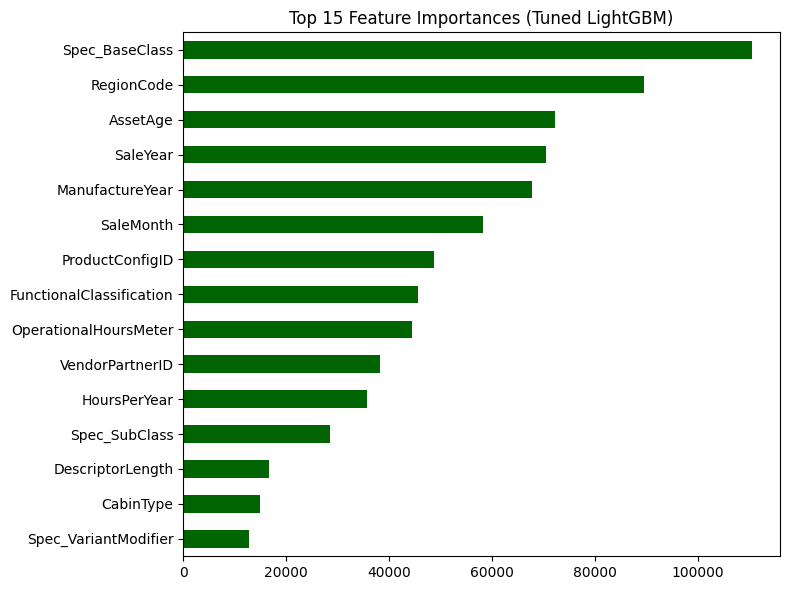

Spec_BaseClass              110411
RegionCode                   89418
AssetAge                     72277
SaleYear                     70523
ManufactureYear              67669
SaleMonth                    58243
ProductConfigID              48765
FunctionalClassification     45681
OperationalHoursMeter        44373
VendorPartnerID              38195
HoursPerYear                 35649
Spec_SubClass                28430
DescriptorLength             16684
CabinType                    14862
Spec_VariantModifier         12664
dtype: int32


In [31]:
importances = pd.Series(lgbm_tuned.feature_importances_, index=X_train_lgb.columns)
importances = importances.sort_values(ascending=False).head(15)

fig, ax = plt.subplots(figsize=(8, 6))
importances.plot(kind="barh", ax=ax, color="darkgreen")
ax.set_title("Top 15 Feature Importances (Tuned LightGBM)")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

print(importances)

In [32]:
final_comparison_df = pd.DataFrame({
    "Model": list(results.keys()),
    "RMSLE": list(results.values())
}).sort_values("RMSLE").reset_index(drop=True)

final_comparison_df

,Model,RMSLE
0,LightGBM (tuned),0.199278
1,LightGBM (RandomizedSearchCV tuned),0.199664
2,LightGBM,0.212044
3,RandomForest,0.223525
4,MLPRegressor,0.279581


## Final Predictions & Submission
Running the same preprocessing on test data and generating submission.csv.


In [33]:
test_num = pd.DataFrame(num_imputer.transform(test[num_cols]), columns=num_cols, index=test.index)

test_cat = test[cat_cols_all].copy()
for col in cat_cols_all:
    test_cat[col] = test_cat[col].astype("category").cat.set_categories(X_train_lgb[col].cat.categories)

X_test_lgb = pd.concat([test_num, test_cat], axis=1)
X_test_lgb = clean_feature_names(X_test_lgb)

# align column order to match training exactly
X_test_lgb = X_test_lgb[X_train_lgb.columns]

test_pred_log = lgbm_tuned.predict(X_test_lgb)
test_pred = np.clip(np.expm1(test_pred_log), 0, None)

submission = pd.DataFrame({
    "TransactionID": test["TransactionID"],
    "TargetValue": test_pred
})

submission.to_csv("submission.csv", index=False)
print("Submission saved:", submission.shape)
submission.head()

Submission saved: (15000, 2)


,TransactionID,TargetValue
0,1139307,66679.805278
1,1139419,73678.923616
2,1139482,32069.112203
3,1139522,19023.424907
4,1139684,10244.348609


In [34]:
print(submission["TargetValue"].describe())
print("Train TargetValue describe:\n", train["TargetValue"].describe())

count     15000.000000
mean      40913.643196
std       24958.637859
min        6830.989535
25%       20945.409416
50%       34607.019796
75%       56411.506120
max      138748.883136
Name: TargetValue, dtype: float64
Train TargetValue describe:
 count    138701.000000
mean      41521.874047
std       26361.125948
min        7500.000000
25%       20500.000000
50%       35000.000000
75%       57000.000000
max      142000.000000
Name: TargetValue, dtype: float64


In [35]:
# DATA_PATH = "/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge"

# train = pd.read_csv(f"{DATA_PATH}/train.csv", low_memory=False)

In [36]:
# lgb = lgb.LGBMClassifier(random_state=42)
# parameters = {"n_estimators" : randint(100,600
#                                       "learning_rate": 0.03
#                                       "num_leaves": 50)}
# random = RandomizedSearchCV( estimatpr = lgb
#                            param_distribution = params
# n_iter = 100
# cv=5,
# random_state=42)


# **MILESTONES**

In [37]:
# import pandas as pd
# train = pd.read_csv('/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/train.csv')
# test = pd.read_csv('/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/test.csv')

# print("shape of train:", train.shape)
# print("shape of test:", test.shape)

# print("\ntarget column:")
# print(set(train.columns) - set(test.columns))

In [38]:
# cols=train.select_dtypes(include=['int64','float64'])
# print(len(cols.columns))

In [39]:
# missing=train.isnull().mean()*100
# print(missing.sort_values(ascending=False).head(20))
# print(missing['col5'])

In [40]:
# print(round(missing['OperationalHoursMeter'],2))

In [41]:
# print(train['TargetValue'].median())

In [42]:
# print(train['ManufactureYear'].mode()[0])

In [43]:
# train['TransactionDate']=pd.to_datetime(train['TransactionDate'])
# print(train['TransactionDate'].min())

In [44]:
# print(train['Spec_BaseClass'].nunique())

In [45]:
# print(train['RegionCode'].value_counts().head())

In [46]:
# print(train.groupby('RegionCode')['TargetValue'].mean().sort_values(ascending=False).head(10))

In [47]:
# print(train['UtilizationTier'].value_counts(dropna=False))

In [48]:
# print(train['TargetValue'].corr(train['OperationalHoursMeter']))

In [49]:
# print(train['FunctionalClassification'].value_counts().head())

In [50]:
# import pandas as pd
# train = pd.read_csv('/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/train.csv', low_memory=False)
# test = pd.read_csv('/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/test.csv', low_memory=False)

# median_price=train['TargetValue'].median()

# submission = pd.DataFrame({'TransactionID': test['TransactionID'], 
#                            'TargetValue': median_price})

# submission.to_csv('submission.csv', index=False)

# print("done")

In [51]:
# import os
# print(os.listdir('.'))

In [52]:
# import os

# for dirname, _, filenames in os.walk('/kaggle/input'):
#     print(dirname)
#     for filename in filenames:
#         print("   ", filename)

In [53]:
# import pandas as pd
# import numpy as np
# train = pd.read_csv(
#     "/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/train.csv",
#     low_memory=False
# )

# test = pd.read_csv(
#     "/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/test.csv",
#     low_memory=False
# )

In [54]:
# train['TransactionDate'] = pd.to_datetime(train['TransactionDate'])
# train['TransactionYear'] = train['TransactionDate'].dt.year
# train['TransactionQuarter'] = train['TransactionDate'].dt.quarter
# train['AssetAge'] = train['TransactionYear'] - train['ManufactureYear']
# train['DescriptorLength'] = train['Spec_FullDescriptor'].astype(str).str.len()
# train['HasOperationalHours'] = train['OperationalHoursMeter'].notna().astype(int)
# train['HasVariantModifier'] = train['Spec_VariantModifier'].notna().astype(int)

In [55]:
# train['AssetAge'].value_counts()

In [56]:
# train.groupby('TransactionQuarter')['TargetValue'].mean()

In [57]:
# train['DescriptorLength'].max()

In [58]:
# train['HasOperationalHours'].sum()

In [59]:
# (train['HasVariantModifier'].mean())*100

In [60]:
# round(train['ManufactureYear'].mean(),2)

In [61]:
# encoded = pd.get_dummies(
#     train, columns=['RegionCode','CabinType','UtilizationTier'], drop_first=True
# )

In [62]:
# new_cols = [col for col in encoded.columns if col not in train.columns]
# len(new_cols)

In [63]:
# numeric = train.select_dtypes(include=np.number)
# corr=numeric.corr()

In [64]:
# corr['TargetValue'].abs().sort_values(ascending=False)

In [65]:
# from sklearn.impute import SimpleImputer
# from sklearn.preprocessing import StandardScaler
# from sklearn.model_selection import train_test_split

In [66]:
# X = encoded.copy()
# X = X.drop(columns=['TargetValue','TransactionDate'])
# y = train['TargetValue']

In [67]:
# bool_cols = X.select_dtypes(bool).columns
# X[bool_cols] = X[bool_cols].astype(int)

In [68]:
# X=X.select_dtypes(include=np.number)

In [69]:
# imputer = SimpleImputer(strategy='mean')

# X = pd.DataFrame(
#     imputer.fit_transform(X),
#     columns=X.columns
# )

In [70]:
# scaler = StandardScaler()

# cols = ['ManufactureYear','OperationalHoursMeter','AssetAge']

# X[cols] = scaler.fit_transform(X[cols])

In [71]:
# X_train, X_valid, y_train, y_valid = train_test_split(
#     X,
#     y,
#     test_size=0.20,
#     random_state=42
# )

In [72]:
# X_train.shape

In [73]:
# len(new_cols)

In [74]:
# X_valid.shape

In [75]:
# train['ManufactureYear'] = train['ManufactureYear'].replace([1000,1001], np.nan)
# train['SaleYear'] = pd.to_datetime(train['TransactionDate']).dt.year
# train['AssetAge'] = train['SaleYear'] - train['ManufactureYear']
# train['AssetAge'].median()

In [76]:
# threshold = 0.8 * len(train)
# dropped_cols = train.columns[train.isnull().sum() > threshold]
# len(dropped_cols)

In [77]:
# train['SaleYear'] = pd.to_datetime(train['TransactionDate']).dt.year
# train['SaleYear'].mode()

In [78]:
# train['CabinType'].fillna("Missing").eq("Missing").sum()

In [79]:
# train['ManufactureYear'] = train['ManufactureYear'].replace([1000,1001], np.nan)
# train['SaleYear'] = pd.to_datetime(train['TransactionDate']).dt.year
# train['AssetAge'] = train['SaleYear'] - train['ManufactureYear']
# train['HoursPerYear'] = train['OperationalHoursMeter'] / train['AssetAge']
# hours = train['HoursPerYear'].replace([np.inf, -np.inf], np.nan)
# hours.median()

In [80]:
# import numpy as np
# log_target = np.log1p(train['TargetValue'])
# log_target.std()

In [81]:
# from sklearn.preprocessing import OrdinalEncoder
# temp = train[['UtilizationTier']].fillna('Uspecified')
# encoder = OrdinalEncoder()
# temp['Encoded'] = encoder.fit_transform(temp[['UtilizationTier']])
# temp['Encoded'].nunique()

In [82]:
# import os

# for dirname, _, filenames in os.walk('/kaggle/input'):
#     print(dirname)
#     for filename in filenames:
#         print("   ", filename)

In [83]:
# from sklearn.model_selection import train_test_split
# df = train.copy()
# df["UtilizationTier"] = df["UtilizationTier"].fillna("Unknown")
# df["PriceBand"] = pd.qcut(df["TargetValue"], q=5, labels=False)

# X = df.drop(columns="TargetValue")
# y = df["TargetValue"]

# X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.30, random_state=42,stratify=df["PriceBand"])
# X_train_ns, X_valid_ns, y_train_ns, y_valid_ns = train_test_split(X, y, test_size=0.30, random_state=42,stratify=None)

# p1 = X_valid["PriceBand"].value_counts(normalize=True).sort_index()
# p2 = X_valid_ns["PriceBand"].value_counts(normalize=True).sort_index()

# print(round((p1-p2).abs().max(), 4))

In [84]:
# import pandas as pd
# import numpy as np
# from sklearn.model_selection import train_test_split, RandomizedSearchCV
# from sklearn.impute import SimpleImputer
# from sklearn.preprocessing import OneHotEncoder, StandardScaler
# from sklearn.compose import ColumnTransformer
# from sklearn.pipeline import Pipeline
# from sklearn.ensemble import RandomForestRegressor, AdaBoostRegressor
# from sklearn.neural_network import MLPRegressor
# from sklearn.metrics import mean_absolute_error

In [85]:
# cat_cols = ["UtilizationTier", "DrivetrainType", "CabinType", "AssetScaleFactor"]
# num_cols = ["ManufactureYear", "OperationalHoursMeter"]

# cat_pipe = Pipeline([
#     ("imputer", SimpleImputer(strategy="most_frequent")),
#     ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=True))
# ])
# num_pipe = Pipeline([
#     ("imputer", SimpleImputer(strategy="mean")),
#     ("scaler", StandardScaler())
# ])

# preprocessor = ColumnTransformer([
#     ("cat", cat_pipe, cat_cols),
#     ("num", num_pipe, num_cols)
# ], remainder="drop")

# X_train_proc = preprocessor.fit_transform(X_train)
# X_valid_proc = preprocessor.transform(X_valid)

# print(round(X_train_proc.sum(), 3))

In [86]:
# param_dist = {"n_estimators": [50, 100, 200], "max_depth": [5, 10, 15]}
# rf = RandomForestRegressor(random_state=42)
# search = RandomizedSearchCV(
#     rf, param_distributions=param_dist, n_iter=5, cv=3,
#     random_state=42, n_jobs=-1
# )
# search.fit(X_train_proc, y_train)
# print(search.best_params_['n_estimators'])


In [87]:
# ada = AdaBoostRegressor(n_estimators=50, random_state=42)
# ada.fit(X_train_proc, y_train)
# print("Q4 variance:", round(np.var(ada.estimator_errors_), 4))


In [88]:
# rf5 = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42)
# rf5.fit(X_train_proc, y_train)
# print(int(np.argmax(rf5.feature_importances_)))


In [89]:
# N = X_train_proc.shape[1]
# weights = N*128 + 128*64 + 64*32 + 32*1
# print(N, " total weights:", weights)


In [90]:
# mlp7 = MLPRegressor(hidden_layer_sizes=(128,64,32), activation="relu",
#                      solver="adam", max_iter=5, batch_size=32, random_state=42)
# mlp7.fit(X_train_proc, y_train)
# print(round(mlp7.loss_, 4))

In [91]:
# mlpA = MLPRegressor(hidden_layer_sizes=(100,), max_iter=5, random_state=42, alpha=0.0001)
# mlpA.fit(X_train_proc, y_train)
# maeA = mean_absolute_error(y_train, mlpA.predict(X_train_proc))

# mlpB = MLPRegressor(hidden_layer_sizes=(100,), max_iter=5, random_state=42, alpha=1.0)
# mlpB.fit(X_train_proc, y_train)
# maeB = mean_absolute_error(y_train, mlpB.predict(X_train_proc))
# print(round(abs(maeA - maeB), 4))

In [92]:
# pred_valid = mlp7.predict(X_valid_proc)
# print("Q9 validation MAE:", round(mean_absolute_error(y_valid, pred_valid), 4))

In [93]:
#----------------------------------------------